# Laboratorio N°3 – Circuito 1 – Caso 1: amplificador compuesto **VFA + VFA** (LM324 + LM324)

**Qué hace este cuaderno:** diseña el amplificador compuesto, calcula todo lo que pide la consigna, grafica los diagramas de Bode y la respuesta al escalón, y arma la tabla final comparando **teoría vs. simulación (LTSpice)**.


| Consigna | Qué se hace | Sección |
|---|---|---|
| a.1 Diseñar el amplificador | Calcular Avf2, R2, Rf y el polo desplazado | 2 |
| a.2 Calcular BW potencial, polo de lazo cerrado y BW a −3 dB | Fórmulas analíticas + verificación numérica | 3, 4, 5 |
| a.3 Medir el BW a −3 dB | Se carga el valor medido en LTSpice y se compara | 7, 9 |
| a.4 Estimar el margen de fase desde el escalón | Sobrepico → ζ → margen de fase | 8 |

**Circuito:** A01 (LM324) con realimentación global Ri–Rf; A02 (LM324) dentro del lazo con realimentación local R1–R2. Ambos son no inversores.

## 1. Preparación

La siguiente celda carga las librerías de Python que se usan:

* `numpy`: cálculos con números y polinomios.
* `matplotlib`: gráficos.
* `pandas`: tablas.
* `scipy.signal`: simula la respuesta al escalón.

También crea la carpeta `salidas_caso1` donde se guardan las figuras y tablas para el informe.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
from IPython.display import display

plt.rcParams.update({'figure.figsize': (10, 6), 'axes.grid': True, 'grid.alpha': 0.4, 'font.size': 11})

CARPETA = 'salidas_caso1'
os.makedirs(CARPETA, exist_ok=True)
print('Listo. Las figuras y tablas se guardarán en la carpeta:', CARPETA)

Listo. Las figuras y tablas se guardarán en la carpeta: salidas_caso1


## 2. Datos y diseño (consigna a.1)

### 2.1 Datos de partida

Se cargan los datos del LM324 (Tabla 1 del informe) y los requerimientos:

* **Ad0 = 100 dB**, **f1 = 10 Hz** (polo dominante), **f2 = 5,06 MHz** (segundo polo).
* **fT = Ad0 · f1 = 1 MHz**: producto ganancia–ancho de banda.
* **Avf = 20 dB** de ganancia global y **máxima planicidad de módulo (MPM)**, es decir **Qp = 1/√2 = 0,707**.
* **Ri = R1 = 10 kΩ**: son las resistencias a tierra de cada lazo, elegidas libremente (las demás se calculan a partir de ellas).

In [2]:
# --- LM324 ---
Ad0_dB = 100.0          # ganancia de lazo abierto [dB]
f1 = 10.0               # primer polo [Hz]
f2 = 5.06e6             # segundo polo [Hz]

Ad0 = 10**(Ad0_dB/20)   # ganancia de lazo abierto en veces (dB -> V/V)
fT = Ad0*f1             # producto ganancia-ancho de banda [Hz]

# --- Requerimientos ---
Avf_dB = 20.0           # ganancia global pedida [dB]
Qp = 1/np.sqrt(2)       # máxima planicidad de módulo

# --- Resistencias elegidas libremente ---
Ri = 10e3               # a tierra, lazo global [ohm]
R1 = 10e3               # a tierra, lazo local de A02 [ohm]

print(f'Ad0 = {Ad0:,.0f} V/V  |  fT = {fT/1e6:.2f} MHz  |  Qp = {Qp:.4f}')

Ad0 = 100,000 V/V  |  fT = 1.00 MHz  |  Qp = 0.7071


### 2.2 Cálculo del diseño

Las fórmulas son las del marco teórico:

1. **Ganancia global:** $A_{vf}=10^{A_{vf(dB)}/20}=10$ y el factor de realimentación $K=1/A_{vf}=0{,}1$.
2. **Ganancia del segundo amplificador.** Se baja la ganancia de A02 con su lazo local para correr su polo a mayor frecuencia (compensación por *separación de polos*). Para obtener MPM:
$$A_{vf2}=Q_p\,\sqrt{A_{vf}}$$
3. **Resistencias** (ambos amplificadores son no inversores, $A=1+R_{f}/R_{i}$):
$$R_f=R_i\,(A_{vf}-1)\qquad\qquad R_2=R_1\,(A_{vf2}-1)$$
4. **Polo desplazado de A02:** como su ganancia es $A_{vf2}$, su ancho de banda es
$$f_{px}=\frac{f_T}{A_{vf2}}$$

In [3]:
Avf  = 10**(Avf_dB/20)      # ganancia global en veces
K    = 1/Avf                # factor de realimentación global
Avf2 = Qp*np.sqrt(Avf)      # ganancia local de A02 para MPM
Rf   = Ri*(Avf - 1)         # resistencia de realimentación global
R2   = R1*(Avf2 - 1)        # resistencia de realimentación local
fpx  = fT/Avf2              # polo desplazado de A02 [Hz]

tabla_diseno = pd.DataFrame({
    'Parámetro': ['Ganancia global', 'Factor de realimentación', 'Ganancia del segundo amplificador',
                  'Resistencia de entrada global', 'Resistencia de realimentación global',
                  'Resistencia de entrada local', 'Resistencia de realimentación local', 'Frecuencia del polo desplazado'],
    'Símbolo': ['Avf', 'K', 'Avf2', 'Ri', 'Rf', 'R1', 'R2', 'fpx'],
    'Valor': [f'{Avf:.1f}', f'{K:.2f}', f'{Avf2:.4f}', f'{Ri/1e3:.3f}', f'{Rf/1e3:.3f}',
              f'{R1/1e3:.3f}', f'{R2/1e3:.3f}', f'{fpx/1e3:.1f}'],
    'Unidad': ['V/V (20 dB)', '-', 'V/V', 'kΩ', 'kΩ', 'kΩ', 'kΩ', 'kHz']
}).set_index('Parámetro')

print('TABLA 1 – Parámetros de diseño')
display(tabla_diseno)

TABLA 1 – Parámetros de diseño


,Símbolo,Valor,Unidad
Parámetro,,,
Ganancia global,Avf,10.0,V/V (20 dB)
Factor de realimentación,K,0.10,-
Ganancia del segundo amplificador,Avf2,2.2361,V/V
Resistencia de entrada global,Ri,10.000,kΩ
Resistencia de realimentación global,Rf,90.000,kΩ
Resistencia de entrada local,R1,10.000,kΩ
Resistencia de realimentación local,R2,12.361,kΩ
Frecuencia del polo desplazado,fpx,447.2,kHz


## 3. Cálculos analíticos (consigna a.2)

Con el diseño hecho, la **ganancia de lazo** $T(s)=K\cdot A_1(s)\cdot A_{2f}(s)$ se aproxima con **dos polos**: el polo dominante $f_1$ de A01 y el polo desplazado $f_{px}$ de A02:
$$T(s)=\frac{T_0}{\left(1+\dfrac{s}{\omega_1}\right)\left(1+\dfrac{s}{\omega_{px}}\right)}\qquad T_0=K\,A_{d0}\,A_{vf2}$$

A partir de eso se obtienen las magnitudes que pide la consigna:

| Magnitud | Fórmula |
|---|---|
| **Ancho de banda potencial** (punto crítico $G$ del compuesto sin compensar, $\vert T\vert=1$ con pendiente −40 dB/dec) | $f_G=\dfrac{f_T}{\sqrt{A_{vf}}}$ |
| Frecuencia de cruce de la ganancia de lazo **ya compensada** (pendiente −20 dB/dec) | $f_{Gc}\simeq K\,A_{vf2}\,f_T$ |
| **Polos de lazo cerrado** | raíces de $s^2+(\omega_1+\omega_{px})\,s+\omega_1\omega_{px}(1+T_0)=0$ |
| Frecuencia de los polos (natural) y factor de calidad | $\omega_p=\sqrt{\omega_1\,\omega_{px}\,(1+T_0)}$ , $\;Q_p=\dfrac{\omega_p}{\omega_1+\omega_{px}}$ , $\;\zeta=\dfrac{1}{2Q_p}$ |
| Polo complejo | $s=-\dfrac{\omega_p}{2Q_p}\pm j\,\omega_p\sqrt{1-\dfrac{1}{4Q_p^2}}$ |
| **Ancho de banda real (−3 dB)** | $f_H=f_p\sqrt{a+\sqrt{a^2+1}}$ con $a=1-\dfrac{1}{2Q_p^2}$ (para $Q_p=0{,}707$ resulta $f_H=f_p$) |
| Cruce **exacto** de la ganancia de lazo compensada | solución de $\vert T(jf_{Gc})\vert=1$ ; para MPM, $\dfrac{f_{Gc}}{f_p}=\Omega_G=0{,}644$ (apunte, Ec. 6.15 y 6.16) |
| Margen de fase | $M_\varphi=180^\circ-\arctan\dfrac{f_{Gc}}{f_1}-\arctan\dfrac{f_{Gc}}{f_{px}}$ ; para MPM, $M_\varphi=90^\circ-\arctan(\Omega_G\,Q_p)=65{,}5^\circ$ (Ec. 6.17) |

**Dos frecuencias distintas, no hay que confundirlas:** el *potencial* $f_G=f_T/\sqrt{A_{vf}}$ es el límite de la estructura compuesta (apunte, sección 7.3); la compensación por separación de polos lo **recupera** como ancho de banda real, porque con MPM $f_H=f_p=f_{px}/\sqrt2=f_T/\sqrt{A_{vf}}$. En cambio $f_{Gc}$ es el cruce de la ganancia de lazo compensada, y es la que se mide en LTSpice sobre el circuito de ganancia de lazo; para MPM se cumple $f_H=f_p=f_{px}/\sqrt2$ y $f_{Gc}\simeq0{,}644\,f_p$.

La celda calcula además la frecuencia de cruce exacta con dos polos (resolviendo $|T|=1$), el cociente $\Omega_G=f_{Gc}/f_p$ y el margen de fase por las dos vías (con los polos de $T$ y con la fórmula del apunte), que deben coincidir.

In [4]:
w1  = 2*np.pi*f1            # los polos se pasan a rad/s para las fórmulas
wpx = 2*np.pi*fpx

T0 = K*Ad0*Avf2                                  # ganancia de lazo en continua
fG_pot = fT/np.sqrt(Avf)                         # ANCHO DE BANDA POTENCIAL (compuesto sin compensar)
fGc_as = K*Avf2*fT                               # cruce de 0 dB de T ya compensada (asintótico)

wp = np.sqrt(w1*wpx*(1 + T0))                    # frecuencia natural de los polos de lazo cerrado
fp = wp/(2*np.pi)
Q  = wp/(w1 + wpx)                               # factor de calidad
zeta = 1/(2*Q)                                   # amortiguamiento

sigma = wp/(2*Q)                                 # parte real del polo (rad/s)
wd = wp*np.sqrt(1 - 1/(4*Q**2))                  # parte imaginaria del polo (rad/s)
polo_LC = complex(-sigma, wd)/(2*np.pi)          # POLO DE LAZO CERRADO en Hz

a = 1 - 1/(2*Q**2)
fH_an = fp*np.sqrt(a + np.sqrt(a**2 + 1))        # ANCHO DE BANDA REAL (-3 dB)

# Cruce de 0 dB exacto con 2 polos: |T|=1  ->  ecuación de 2° grado en x = f^2
c2 = 1/(f1**2*fpx**2); c1 = 1/f1**2 + 1/fpx**2; c0 = 1 - T0**2
x = (-c1 + np.sqrt(c1**2 - 4*c2*c0))/(2*c2)
fGc_ex = np.sqrt(x)
Mphi_an = 180 - np.degrees(np.arctan(fGc_ex/f1)) - np.degrees(np.arctan(fGc_ex/fpx))

# Verificación con el apunte (Ec. 6.15 a 6.17), normalizando con la frecuencia de los polos fp
OmegaG = fGc_ex/fp                                          # debe dar ≈ 0,644 para MPM
Omega_apunte = np.sqrt((-1/Q**2 + np.sqrt(1/Q**4 + 4))/2)   # raíz de  Ω^4 + Ω^2/Q^2 - 1 = 0
Mphi_apunte = 90 - np.degrees(np.arctan(Omega_apunte*Q))    # Mφ = 90° - arctg(ΩG·Qp)

tabla_analitica = pd.DataFrame({
    'Magnitud': ['Ganancia de lazo en continua T0', 'Ancho de banda potencial fG = fT/√Avf', 'Cruce de T compensada (asintótico) K·Avf2·fT',
                 'Frecuencia de los polos fp', 'Factor de calidad Qp', 'Amortiguamiento ζ',
                 'Polo de lazo cerrado (parte real)', 'Polo de lazo cerrado (parte imaginaria)',
                 'Ancho de banda real fH (-3 dB)', 'Frecuencia de cruce exacta fGc (2 polos)', 'ΩG = fGc/fp', 'Margen de fase (2 polos)', 'Margen de fase con fórmula del apunte (6.17)'],
    'Valor': [f'{T0:,.0f}  ({20*np.log10(T0):.1f} dB)', f'{fG_pot/1e3:.1f}', f'{fGc_as/1e3:.1f}', f'{fp/1e3:.1f}', f'{Q:.3f}', f'{zeta:.3f}',
              f'{polo_LC.real/1e3:.1f}', f'±{abs(polo_LC.imag)/1e3:.1f}', f'{fH_an/1e3:.1f}', f'{fGc_ex/1e3:.1f}', f'{OmegaG:.4f}', f'{Mphi_an:.2f}', f'{Mphi_apunte:.2f}'],
    'Unidad': ['', 'kHz', 'kHz', 'kHz', '', '', 'kHz', 'kHz', 'kHz', 'kHz', '', '°', '°']
}).set_index('Magnitud')

print('TABLA 2 – Resultados analíticos (modelo de 2 polos)')
display(tabla_analitica)

TABLA 2 – Resultados analíticos (modelo de 2 polos)


,Valor,Unidad
Magnitud,,
Ganancia de lazo en continua T0,"22,361 (87.0 dB)",
Ancho de banda potencial fG = fT/√Avf,316.2,kHz
Cruce de T compensada (asintótico) K·Avf2·fT,223.6,kHz
Frecuencia de los polos fp,316.2,kHz
Factor de calidad Qp,0.707,
Amortiguamiento ζ,0.707,
Polo de lazo cerrado (parte real),-223.6,kHz
Polo de lazo cerrado (parte imaginaria),±223.6,kHz
Ancho de banda real fH (-3 dB),316.2,kHz


## 4. Modelo completo del circuito (para verificar numéricamente)

Las fórmulas anteriores usan solo 2 polos. El circuito real en LTSpice tiene **4 polos**: cada LM324 tiene $f_1$ y $f_2$. Para ver cuánto afecta el segundo polo, se arman las funciones de transferencia como cociente de polinomios (`num`/`den`, coeficientes de la mayor a la menor potencia de `s`):

* **Modelo de 2 polos:** el de la sección 3.
* **Modelo de 4 polos:** cada amplificador es $A(s)=\dfrac{A_{d0}\,\omega_1\omega_2}{(s+\omega_1)(s+\omega_2)}$. A02 se cierra con su lazo local, $A_{2f}=\dfrac{A_2}{1+A_2/A_{vf2}}$ (línea `den_A2f`). El camino directo es $G=A_1\cdot A_{2f}$.

Luego se calculan sobre una grilla de frecuencias (de 1 Hz a 1 GHz):

* `T` = ganancia de lazo $=K\cdot G$.
* `Acl` = ganancia a lazo cerrado $=\dfrac{G}{1+K\,G}$ (fórmula de Black). Su denominador, `den_cl`, tiene como raíces los **polos de lazo cerrado**.

> Este modelo de 4 polos es el equivalente teórico del circuito simulado en LTSpice.

In [5]:
w2 = 2*np.pi*f2

# ---- Modelo de 2 polos: G(s) = Ad0*Avf2 / ((1+s/w1)(1+s/wpx)) ----
num_2p = np.array([Ad0*Avf2*w1*wpx])
den_2p = np.convolve([1, w1], [1, wpx])

# ---- Modelo de 4 polos ----
numA = np.array([Ad0*w1*w2])                   # un LM324:  numA/denA
denA = np.array([1, w1 + w2, w1*w2])
den_A2f = np.polyadd(denA, numA/Avf2)          # A02 con su lazo local cerrado
num_4p = np.convolve(numA, numA)               # A1 * A2f
den_4p = np.convolve(denA, den_A2f)

# ---- Respuesta en frecuencia ----
f = np.logspace(0, 9, 100000)                  # de 1 Hz a 1 GHz

def respuesta(num, den, f):
    s = 1j*2*np.pi*f                           # s = j·2·pi·f
    return np.polyval(num, s)/np.polyval(den, s)

def lazo(num_G, den_G):
    # Devuelve T(f), Acl(f) y el denominador de lazo cerrado
    num_T = K*num_G
    den_cl = np.polyadd(den_G, num_T)          # 1 + K*G = 0
    return respuesta(num_T, den_G, f), respuesta(num_G, den_cl, f), den_cl

T_2p, Acl_2p, den_cl_2p = lazo(num_2p, den_2p)
T_4p, Acl_4p, den_cl_4p = lazo(num_4p, den_4p)
print('Modelos armados. Puntos de frecuencia:', len(f))

Modelos armados. Puntos de frecuencia: 100000


## 5. Resultados numéricos del lazo (consigna a.2)

Con las curvas calculadas se miden las cantidades que interesan:

* **Frecuencia crítica $f_{Gc}$:** donde el módulo de $T$ cruza 0 dB.
* **Margen de fase:** $M_\varphi=180^\circ+\angle T(f_{Gc})$.
* **Margen de ganancia:** $M_G=-20\log|T|$ en la frecuencia donde la fase de $T$ llega a −180°.
* **Ancho de banda real:** frecuencia donde $|A_{vf}|$ cae 3 dB respecto de su valor en continua.
* **Polos de lazo cerrado:** raíces del denominador de $A_{vf}(s)$ (`np.roots`).

El factor de calidad del par de polos dominante es $Q=\dfrac{|p|}{2\,|\mathrm{Re}(p)|}$.

In [6]:
logf = np.log10(f)

def medir(T, Acl, den_cl):
    magT   = 20*np.log10(np.abs(T))
    faseT  = np.degrees(np.unwrap(np.angle(T)))
    magA   = 20*np.log10(np.abs(Acl))
    faseA  = np.degrees(np.unwrap(np.angle(Acl)))

    # Frecuencia crítica: primer punto donde |T| baja de 0 dB (se interpola entre dos puntos)
    i = np.argmax(magT < 0)
    fGc = np.interp(0, [magT[i], magT[i-1]], [f[i], f[i-1]])
    Mphi = 180 + np.interp(np.log10(fGc), logf, faseT)

    # Margen de ganancia: donde la fase de T llega a -180 grados
    j = np.argmax(faseT < -180)
    if faseT[j] < -180:
        fpc = np.interp(-180, [faseT[j], faseT[j-1]], [f[j], f[j-1]])
        MG = -np.interp(np.log10(fpc), logf, magT)
    else:
        fpc, MG = np.nan, np.inf

    # Ancho de banda a -3 dB (respecto de la ganancia en continua)
    obj = magA[0] - 3.0103
    k = np.argmax(magA < obj)
    BW = np.interp(obj, [magA[k], magA[k-1]], [f[k], f[k-1]])

    # Polos de lazo cerrado (en Hz), ordenados de menor a mayor módulo
    p = np.roots(den_cl)/(2*np.pi)
    p = p[np.argsort(np.abs(p))]
    dom = p[np.imag(p) > 0][0]                 # polo complejo dominante
    return dict(magT=magT, faseT=faseT, magA=magA, faseA=faseA, fGc=fGc, Mphi=Mphi, fpc=fpc, MG=MG,
                BW=BW, polos=p, dom=dom, fp=abs(dom), Q=abs(dom)/(2*abs(dom.real)), Avf0=magA[0])

R2p = medir(T_2p, Acl_2p, den_cl_2p)
R4p = medir(T_4p, Acl_4p, den_cl_4p)

tabla_modelos = pd.DataFrame({
    'Magnitud': ['Frecuencia crítica fGc [kHz]', 'Margen de fase [°]', 'Margen de ganancia [dB]',
                 'Ancho de banda real (-3 dB) [kHz]', 'Frecuencia de los polos fp [kHz]', 'Factor de calidad Qp',
                 'Polo dominante: parte real [kHz]', 'Polo dominante: parte imaginaria [kHz]', 'Ganancia en continua [dB]'],
    'Modelo 2 polos': [f"{R2p['fGc']/1e3:.1f}", f"{R2p['Mphi']:.2f}", '∞', f"{R2p['BW']/1e3:.1f}", f"{R2p['fp']/1e3:.1f}",
                       f"{R2p['Q']:.3f}", f"{R2p['dom'].real/1e3:.1f}", f"±{R2p['dom'].imag/1e3:.1f}", f"{R2p['Avf0']:.2f}"],
    'Modelo 4 polos': [f"{R4p['fGc']/1e3:.1f}", f"{R4p['Mphi']:.2f}", f"{R4p['MG']:.1f}", f"{R4p['BW']/1e3:.1f}", f"{R4p['fp']/1e3:.1f}",
                       f"{R4p['Q']:.3f}", f"{R4p['dom'].real/1e3:.1f}", f"±{R4p['dom'].imag/1e3:.1f}", f"{R4p['Avf0']:.2f}"],
}).set_index('Magnitud')

print('TABLA 3 – Resultados numéricos: modelo de 2 polos vs. modelo de 4 polos')
display(tabla_modelos)
print('\nPolos de lazo cerrado del modelo de 4 polos [kHz]:')
for p in R4p['polos']:
    print(f'   {p.real/1e3:+10.1f} {p.imag/1e3:+10.1f}j')

TABLA 3 – Resultados numéricos: modelo de 2 polos vs. modelo de 4 polos


,Modelo 2 polos,Modelo 4 polos
Magnitud,,
Frecuencia crítica fGc [kHz],203.5,206.1
Margen de fase [°],65.53,62.51
Margen de ganancia [dB],∞,21.4
Ancho de banda real (-3 dB) [kHz],316.2,345.8
Frecuencia de los polos fp [kHz],316.2,330.3
Factor de calidad Qp,0.707,0.746
Polo dominante: parte real [kHz],-223.6,-221.4
Polo dominante: parte imaginaria [kHz],±223.6,±245.1
Ganancia en continua [dB],20.00,20.00



Polos de lazo cerrado del modelo de 4 polos [kHz]:
       -221.4     -245.1j
       -221.4     +245.1j
      -4838.6     -245.1j
      -4838.6     +245.1j


## 6. Diagrama de Bode de lazo cerrado

Se grafica el módulo y la fase de $A_{vf}(s)$ para los dos modelos. Qué mirar:

* La ganancia en banda media debe ser **20 dB**.
* Con MPM la curva de módulo es **plana, sin sobrepasamiento**, y cae suavemente.
* Las líneas verticales marcan $f_1$, $f_{px}$ (polo desplazado), $f_2$ y el ancho de banda a −3 dB.

La figura se muestra acá y se guarda como PDF en `salidas_caso1` para el informe.

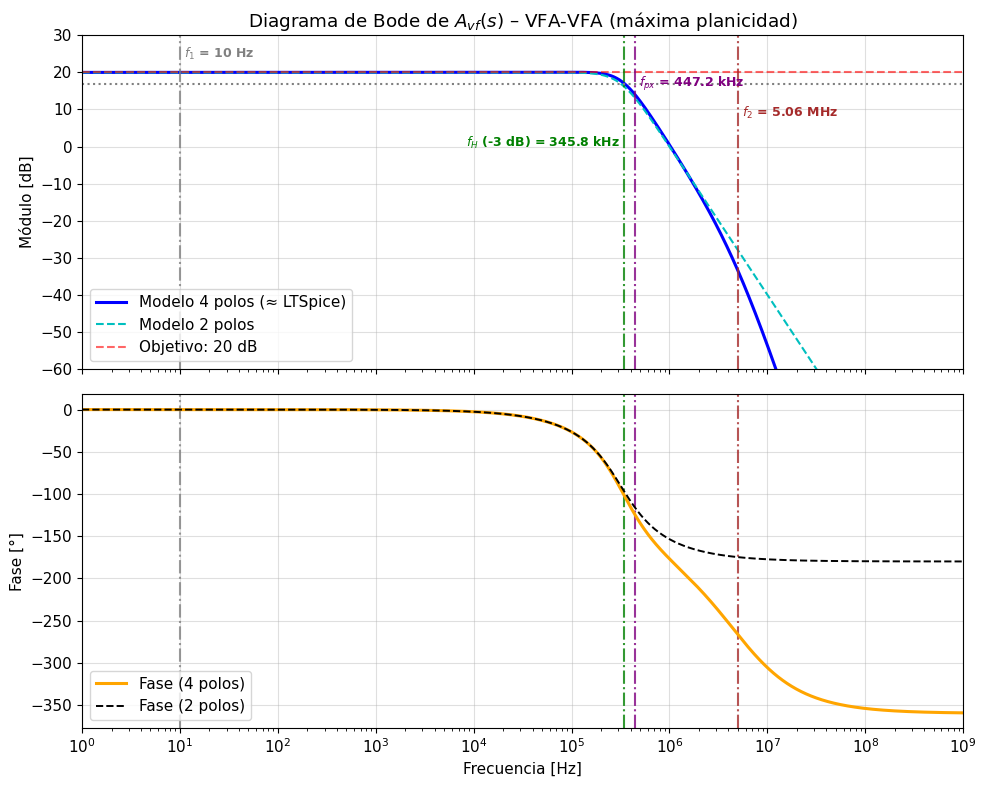

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

ax1.semilogx(f, R4p['magA'], 'b', lw=2.2, label='Modelo 4 polos (≈ LTSpice)')
ax1.semilogx(f, R2p['magA'], 'c--', lw=1.5, label='Modelo 2 polos')
ax1.axhline(Avf_dB, color='r', ls='--', alpha=0.6, label='Objetivo: 20 dB')
ax1.axhline(Avf_dB - 3, color='gray', ls=':')
ax1.set_ylim(-60, 30)
ax1.set_ylabel('Módulo [dB]')
ax1.set_title('Diagrama de Bode de $A_{vf}(s)$ – VFA-VFA (máxima planicidad)')

marcas = [(f1, '$f_1$', 'gray'), (fpx, '$f_{px}$', 'purple'), (f2, '$f_2$', 'brown'), (R4p['BW'], '$f_H$ (-3 dB)', 'green')]
for k, (fr, nombre, color) in enumerate(marcas):
    ax1.axvline(fr, color=color, ls='-.', alpha=0.8)
    ax2.axvline(fr, color=color, ls='-.', alpha=0.8)
    if fr < 1e3:
        etiqueta = f'{nombre} = {fr:.4g} Hz'
    elif fr < 1e6:
        etiqueta = f'{nombre} = {fr/1e3:.4g} kHz'
    else:
        etiqueta = f'{nombre} = {fr/1e6:.3g} MHz'
    if nombre.startswith('$f_H'):                  # esta etiqueta va a la izquierda de su línea
        ax1.text(fr/1.1, 24 - 8*k, etiqueta, color=color, fontsize=9, weight='bold', ha='right')
    else:
        ax1.text(fr*1.1, 24 - 8*k, etiqueta, color=color, fontsize=9, weight='bold')
ax1.legend(loc='lower left')

ax2.semilogx(f, R4p['faseA'], color='orange', lw=2.2, label='Fase (4 polos)')
ax2.semilogx(f, R2p['faseA'], 'k--', lw=1.4, label='Fase (2 polos)')
ax2.set_ylabel('Fase [°]'); ax2.set_xlabel('Frecuencia [Hz]')
ax2.set_xlim(1, 1e9); ax2.legend(loc='lower left')

plt.tight_layout()
fig.savefig(f'{CARPETA}/c1_bode_lazo_cerrado.pdf')
plt.show()

### Diagrama de Bode de la ganancia de lazo $T(s)$

El **margen de fase se define sobre $T(s)$**, no sobre $A_{vf}$. Este gráfico muestra:

* En el módulo: el cruce por 0 dB, que da la frecuencia crítica $f_{Gc}$ (línea verde).
* En la fase: cuánto falta para −180° en ese punto. Esa distancia es el **margen de fase** $M_\varphi$.
* La línea roja de trazos en el módulo es el cruce de 0 dB asintótico de la ganancia de lazo compensada, $K\,A_{vf2}\,f_T$.

Debe coincidir con la medición que se hace en LTSpice sobre el circuito de ganancia de lazo.

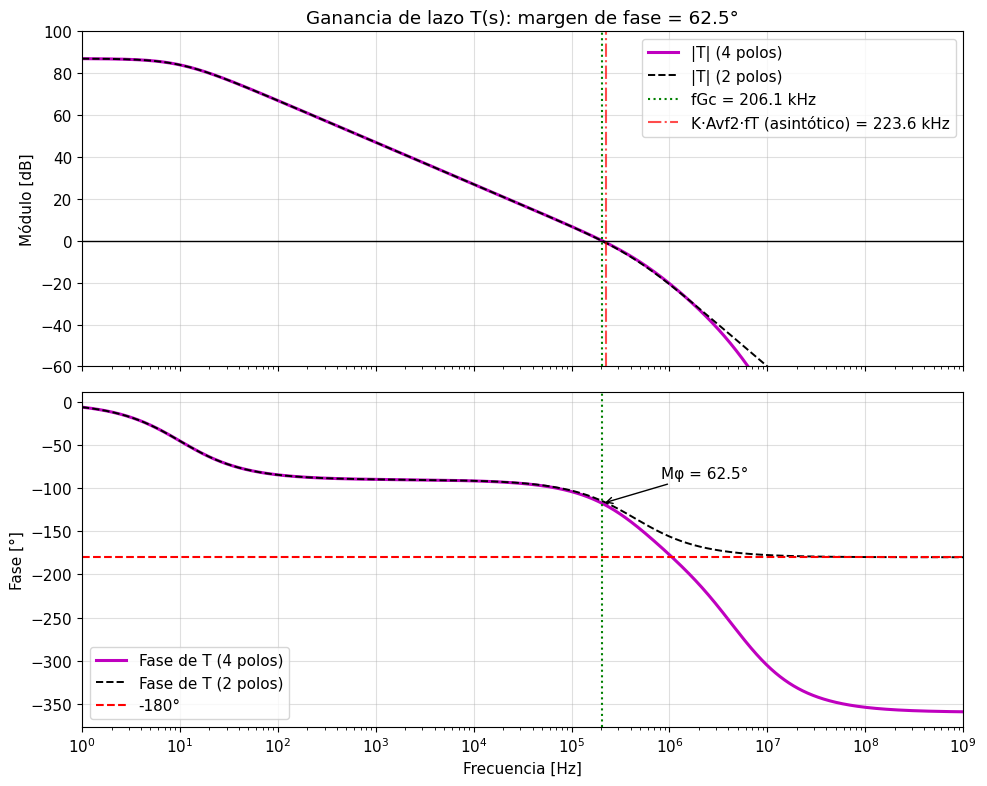

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

ax1.semilogx(f, R4p['magT'], 'm', lw=2.2, label='|T| (4 polos)')
ax1.semilogx(f, R2p['magT'], 'k--', lw=1.4, label='|T| (2 polos)')
ax1.axhline(0, color='k', lw=1)
ax1.axvline(R4p['fGc'], color='g', ls=':', label=f"fGc = {R4p['fGc']/1e3:.1f} kHz")
ax1.axvline(fGc_as, color='r', ls='-.', alpha=0.7, label=f'K·Avf2·fT (asintótico) = {fGc_as/1e3:.1f} kHz')
ax1.set_ylim(-60, 100); ax1.set_ylabel('Módulo [dB]')
ax1.set_title(f"Ganancia de lazo T(s): margen de fase = {R4p['Mphi']:.1f}°")
ax1.legend()

ax2.semilogx(f, R4p['faseT'], 'm', lw=2.2, label='Fase de T (4 polos)')
ax2.semilogx(f, R2p['faseT'], 'k--', lw=1.4, label='Fase de T (2 polos)')
ax2.axhline(-180, color='r', ls='--', label='-180°')
ax2.axvline(R4p['fGc'], color='g', ls=':')
ax2.annotate(f"Mφ = {R4p['Mphi']:.1f}°", xy=(R4p['fGc'], R4p['Mphi'] - 180),
             xytext=(R4p['fGc']*4, R4p['Mphi'] - 150), arrowprops=dict(arrowstyle='->'))
ax2.set_ylabel('Fase [°]'); ax2.set_xlabel('Frecuencia [Hz]')
ax2.set_xlim(1, 1e9); ax2.legend(loc='lower left')

plt.tight_layout()
fig.savefig(f'{CARPETA}/c1_bode_ganancia_lazo.pdf')
plt.show()

## 7. Mediciones de LTSpice (consigna a.3)

**Esta es la única celda que tenés que editar a mano.** Cargá acá lo que mediste en LTSpice. Ya están los valores de tu informe actual (Figuras 16, 17 y 18):

| Variable | Qué es | Dónde se mide en LTSpice |
|---|---|---|
| `fg_sim` | Frecuencia donde la ganancia de lazo cruza 0 dB | Circuito de ganancia de lazo (Fig. 16) |
| `Mphi_sim` | Margen de fase | Idem (`Phase Margin` que muestra LTSpice) |
| `BW_sim` | Ancho de banda a −3 dB | Circuito a lazo cerrado, cursor a 17 dB (Fig. 17) |
| `Vpico_sim`, `Vest_sim` | Tensión pico y de régimen de la salida ante el escalón | Simulación temporal (Fig. 18) |
| `Vin_escalon` | Amplitud del escalón de entrada que usaste | Fuente de entrada |

Si repetís una medición, solo cambiás el número y volvés a ejecutar de esta celda hacia abajo.

In [9]:
# ====== EDITAR ACÁ con las mediciones de LTSpice ======
fg_sim     = 205.994e3   # [Hz]  cruce de 0 dB de la ganancia de lazo
Mphi_sim   = 62.5197     # [°]   margen de fase medido
BW_sim     = 345.013e3   # [Hz]  ancho de banda a -3 dB (lazo cerrado)
Vpico_sim  = 1.0582238   # [V]   pico de la respuesta al escalón (escalón de 0,1 V, Trise = 10 ns)
Vest_sim   = 0.99995428  # [V]   valor de régimen
Vin_escalon = 0.1        # [V]   amplitud del escalón de entrada usado en LTSpice
# =======================================================
print('Mediciones cargadas.')

Mediciones cargadas.


## 8. Respuesta al escalón y margen de fase estimado (consigna a.4)

**Idea:** un sistema subamortiguado supera su valor final al responder a un escalón. El tamaño de ese **sobrepico** indica el amortiguamiento, y éste el margen de fase:

1. Sobrepico porcentual: $\%OS=\dfrac{V_{pico}-V_{est}}{V_{est}}\cdot100$
2. Amortiguamiento: $\zeta=\dfrac{-\ln(\%OS/100)}{\sqrt{\pi^2+\ln^2(\%OS/100)}}$
3. Margen de fase: $M_\varphi=\arctan\!\left(\dfrac{2\zeta}{\sqrt{\sqrt{1+4\zeta^4}-2\zeta^2}}\right)$

La celda aplica esas tres ecuaciones a **tres casos**: el modelo de 2 polos, el de 4 polos (ambos con `scipy`) y **tu medición de LTSpice**. Después grafica la respuesta teórica y marca el pico medido.

> Estas relaciones son exactas para sistemas de 2° orden; con 4 polos son una estimación (por eso difieren ~1–2° del margen de fase medido sobre el lazo).

TABLA 4 – Respuesta al escalón y margen de fase estimado


,Modelo 2 polos,Modelo 4 polos,LTSpice (medido)
Magnitud,,,
Vpico [V],1.043,1.058,1.058
Vestacionario [V],1.000,1.000,1.000
Sobrepico %OS,4.32,5.82,5.83
Amortiguamiento ζ,0.7071,0.6711,0.6709
Margen de fase estimado [°],65.53,63.57,63.56


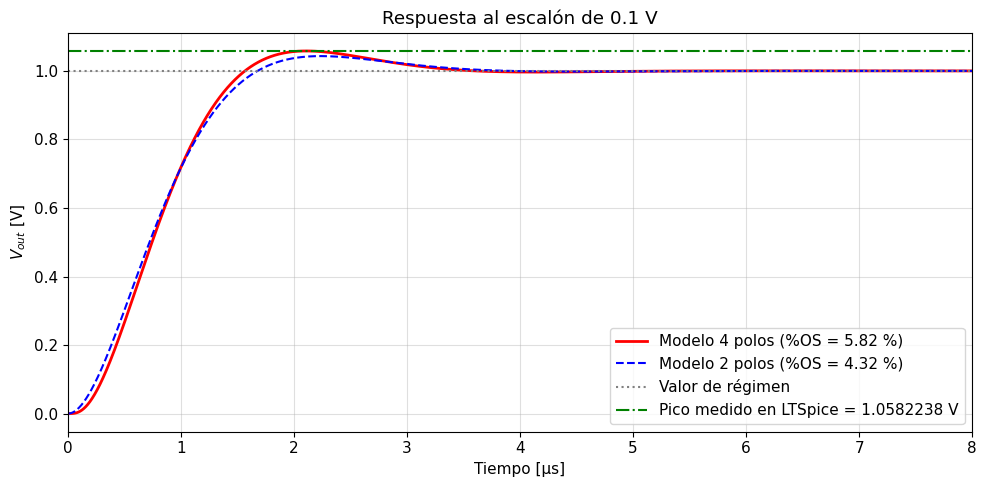

In [10]:
def escalon(den_cl, num_G):
    t = np.linspace(0, 20e-6, 20001)
    t, y = signal.step(signal.TransferFunction(num_G*Vin_escalon, den_cl), T=t)
    return t, y

def sobrepico(Vpico, Vest):
    return (Vpico - Vest)/Vest*100

def zeta_de_OS(OS):                                  # Ecuación del amortiguamiento
    x = np.log(OS/100)
    return -x/np.sqrt(np.pi**2 + x**2)

def MF_de_zeta(z):                                   # Ecuación del margen de fase
    return np.degrees(np.arctan(2*z/np.sqrt(np.sqrt(1 + 4*z**4) - 2*z**2)))

t2, y2 = escalon(den_cl_2p, num_2p)
t4, y4 = escalon(den_cl_4p, num_4p)

OS_2p  = sobrepico(y2.max(), y2[-1])
OS_4p  = sobrepico(y4.max(), y4[-1])
OS_sim = sobrepico(Vpico_sim, Vest_sim)

z_2p, z_4p, z_sim = zeta_de_OS(OS_2p), zeta_de_OS(OS_4p), zeta_de_OS(OS_sim)
MF_2p, MF_4p, MF_sim = MF_de_zeta(z_2p), MF_de_zeta(z_4p), MF_de_zeta(z_sim)

tabla_escalon = pd.DataFrame({
    'Magnitud': ['Vpico [V]', 'Vestacionario [V]', 'Sobrepico %OS', 'Amortiguamiento ζ', 'Margen de fase estimado [°]'],
    'Modelo 2 polos': [f'{y2.max():.3f}', f'{y2[-1]:.3f}', f'{OS_2p:.2f}', f'{z_2p:.4f}', f'{MF_2p:.2f}'],
    'Modelo 4 polos': [f'{y4.max():.3f}', f'{y4[-1]:.3f}', f'{OS_4p:.2f}', f'{z_4p:.4f}', f'{MF_4p:.2f}'],
    'LTSpice (medido)': [f'{Vpico_sim:.3f}', f'{Vest_sim:.3f}', f'{OS_sim:.2f}', f'{z_sim:.4f}', f'{MF_sim:.2f}'],
}).set_index('Magnitud')

print('TABLA 4 – Respuesta al escalón y margen de fase estimado')
display(tabla_escalon)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t4*1e6, y4, 'r', lw=2, label=f'Modelo 4 polos (%OS = {OS_4p:.2f} %)')
ax.plot(t2*1e6, y2, 'b--', lw=1.5, label=f'Modelo 2 polos (%OS = {OS_2p:.2f} %)')
ax.axhline(Vest_sim, color='gray', ls=':', label='Valor de régimen')
ax.axhline(Vpico_sim, color='green', ls='-.', label=f'Pico medido en LTSpice = {Vpico_sim} V')
ax.set_xlim(0, 8); ax.set_xlabel('Tiempo [µs]'); ax.set_ylabel('$V_{out}$ [V]')
ax.set_title(f'Respuesta al escalón de {Vin_escalon:g} V'); ax.legend(loc='lower right')
plt.tight_layout()
fig.savefig(f'{CARPETA}/c1_escalon_teorico.pdf')
plt.show()

## 9. Tabla final: teoría vs. simulación

Se juntan todos los resultados en una sola tabla, uno por fila. Para cada magnitud se muestran:

* **Analítico:** fórmulas cerradas (modelo de 2 polos, sección 3).
* **Modelo 4 polos:** cálculo numérico con el circuito completo (sección 5).
* **LTSpice:** lo que cargaste en la sección 7.
* **Error:** $\varepsilon=\dfrac{\text{teórico}-\text{simulado}}{\text{simulado}}\cdot100$ (igual que en el informe), respecto de cada columna teórica.

Esta es la tabla que va en el informe. Se guarda también como archivo `.csv` y `.tex`.

In [11]:
def error(teo, sim):
    if sim is None or teo is None or (isinstance(teo, float) and teo != teo) or (isinstance(sim, float) and sim != sim):
        return '--'
    return f'{(teo - sim)/sim*100:+.1f}'

def texto(v, esc, dec):
    return '--' if v is None else f'{v*esc:.{dec}f}'

# (nombre, analítico, modelo 4 polos, LTSpice, factor de escala, decimales)
filas = [
    ('Ancho de banda potencial fG = fT/√Avf [kHz]', fG_pot,    None,         None,     1e-3, 1),
    ('Cruce de T compensada, K·Avf2·fT [kHz]',      fGc_as,    R4p['fGc'],    fg_sim,   1e-3, 1),
    ('Cruce de T compensada, exacto (2 polos) [kHz]', fGc_ex, R4p['fGc'],  fg_sim,   1e-3, 1),
    ('Margen de fase del lazo [°]',                 Mphi_an,   R4p['Mphi'],  Mphi_sim, 1,    2),
    ('Frecuencia de los polos fp [kHz]',            fp,        R4p['fp'],    None,     1e-3, 1),
    ('Ancho de banda real fH (-3 dB) [kHz]',        fH_an,     R4p['BW'],    BW_sim,   1e-3, 1),
    ('Sobrepico %OS [%]',                           OS_2p,     OS_4p,        OS_sim,   1,    2),
    ('Margen de fase desde el escalón [°]',         MF_2p,     MF_4p,        MF_sim,   1,    2),
]

tabla_final = pd.DataFrame({
    'Magnitud':        [r[0] for r in filas],
    'Analítico':       [texto(r[1], r[4], r[5]) for r in filas],
    'Modelo 4 polos':  [texto(r[2], r[4], r[5]) for r in filas],
    'LTSpice':         [texto(r[3], r[4], r[5]) for r in filas],
    'Error anal. [%]':  [error(r[1], r[3]) for r in filas],
    'Error 4 polos [%]':    [error(r[2], r[3]) for r in filas],
}).set_index('Magnitud')

print('TABLA FINAL – Caso 1 (VFA-VFA): teoría vs. simulación')
display(tabla_final)
print(f'\nMargen de ganancia (modelo 4 polos): {R4p["MG"]:.1f} dB en {R4p["fpc"]/1e6:.2f} MHz  (todavía no medido en LTSpice)')

TABLA FINAL – Caso 1 (VFA-VFA): teoría vs. simulación


,Analítico,Modelo 4 polos,LTSpice,Error anal. [%],Error 4 polos [%]
Magnitud,,,,,
Ancho de banda potencial fG = fT/√Avf [kHz],316.2,--,--,--,--
"Cruce de T compensada, K·Avf2·fT [kHz]",223.6,206.1,206.0,+8.6,+0.0
"Cruce de T compensada, exacto (2 polos) [kHz]",203.5,206.1,206.0,-1.2,+0.0
Margen de fase del lazo [°],65.53,62.51,62.52,+4.8,-0.0
Frecuencia de los polos fp [kHz],316.2,330.3,--,--,--
Ancho de banda real fH (-3 dB) [kHz],316.2,345.8,345.0,-8.3,+0.2
Sobrepico %OS [%],4.32,5.82,5.83,-25.8,-0.1
Margen de fase desde el escalón [°],65.53,63.57,63.56,+3.1,+0.0



Margen de ganancia (modelo 4 polos): 21.4 dB en 1.06 MHz  (todavía no medido en LTSpice)


## 10. Guardar las tablas para el informe

La celda guarda las tablas en `salidas_caso1`: `.csv` (para abrir en Excel) y `.tex` (para incluir en LaTeX con `\input{...}`; requiere el paquete `booktabs`). Las figuras ya se guardaron como PDF en las secciones 6 y 8.

Si estás en **Google Colab**, además descarga todo en un `.zip`. Fuera de Colab no hace nada más (el aviso amarillo de "google.colab" en VS Code se puede ignorar).

In [12]:
def guardar(df, nombre, titulo, etiqueta):
    df.to_csv(f'{CARPETA}/{nombre}.csv', encoding='utf-8-sig')
    cols = ' & '.join(['Magnitud'] + list(df.columns)) + r' \\'
    lineas = [r'\begin{table}[H]', r'\centering', r'\begin{tabular}{l' + 'c'*len(df.columns) + '}', r'\toprule', cols, r'\midrule']
    for idx, fila in df.iterrows():
        lineas.append(' & '.join([str(idx)] + [str(v) for v in fila.values]).replace('%', r'\%').replace('°', r'$^\circ$').replace('_', r'\_') + r' \\')
    lineas += [r'\bottomrule', r'\end{tabular}', rf'\caption{{{titulo}}}', rf'\label{{{etiqueta}}}', r'\end{table}']
    open(f'{CARPETA}/{nombre}.tex', 'w', encoding='utf-8').write('\n'.join(lineas))

guardar(tabla_diseno,     'tabla_diseno',     'Parámetros de diseño del amplificador compuesto VFA-VFA.', 'tab:diseno_c1')
guardar(tabla_analitica,  'tabla_analitica',  'Resultados analíticos del amplificador compuesto VFA-VFA.', 'tab:analitica_c1')
guardar(tabla_modelos,    'tabla_modelos',    'Resultados numéricos: modelo de 2 polos y de 4 polos.', 'tab:modelos_c1')
guardar(tabla_escalon,    'tabla_escalon',    'Respuesta al escalón y margen de fase estimado.', 'tab:escalon_c1')
guardar(tabla_final,      'tabla_final',      'Comparación entre teoría y simulación (VFA-VFA).', 'tab:final_c1')

print('Archivos en', CARPETA + ':')
for nombre in sorted(os.listdir(CARPETA)):
    print('  ', nombre)

try:    # solo funciona en Google Colab
    import shutil
    from google.colab import files  # type: ignore
    shutil.make_archive('salidas_caso1', 'zip', CARPETA)
    files.download('salidas_caso1.zip')
except ImportError:
    pass

Archivos en salidas_caso1:
   c1_bode_ganancia_lazo.pdf
   c1_bode_lazo_cerrado.pdf
   c1_escalon_teorico.pdf
   fig_bode_ganancia_lazo.pdf
   fig_bode_lazo_cerrado.pdf
   fig_escalon.pdf
   tabla_analitica.csv
   tabla_analitica.tex
   tabla_diseno.csv
   tabla_diseno.tex
   tabla_escalon.csv
   tabla_escalon.tex
   tabla_final.csv
   tabla_final.tex
   tabla_modelos.csv
   tabla_modelos.tex


## 11. Qué mirar para la conclusión del Caso 1

Puntos que conviene discutir en el informe, con lo que muestran las tablas:

1. **El diseño cumple:** ganancia de 20 dB y respuesta plana sin sobrepasamiento en el módulo (MPM).
2. **Potencial vs. real:** el ancho de banda potencial ($f_T/\sqrt{A_{vf}}=316$ kHz) coincide con el ancho de banda real analítico: la compensación lo recupera, a costa de ganancia de lazo ($T_0$ baja de ~$10^{9}$ a ~$2\cdot10^{4}$).
3. **Analítico vs. 4 polos:** el modelo de 2 polos desprecia el segundo polo $f_2$ de cada LM324. Eso hace que el modelo analítico dé un margen de fase mayor (≈65,5°) que el real (≈62,5°) y un ancho de banda menor. Ese es el origen de las diferencias de las columnas de error.
4. **4 polos vs. LTSpice:** coinciden casi exactamente en $f_{Gc}$, margen de fase y ancho de banda; el modelo de 4 polos es una buena representación del circuito simulado.
5. **Sobrepico:** con un escalón de entrada de 0,1 V (salida de 1 V) y flancos de 10 ns, el sobrepico simulado coincide con el del modelo de 4 polos, lo que confirma que no hay efectos de slew rate en pequeña señal. Con un flanco lento (p. ej. 1 µs, comparable al tiempo de subida del circuito) el sobrepico se recorta, por lo que conviene usar flancos rápidos.
6. **Margen de fase por escalón vs. por lazo:** difieren unos grados porque la relación $\zeta \leftrightarrow M_\varphi$ vale exactamente solo para 2° orden.